# Fase 6 - Visão Computacional com YOLO
## FIAP - Inteligência Artificial

**Aluno:** Henrique Abreu  
**RM:** 572248  
**Data de entrega:** 2026-10-14

---

Nesse notebook eu vou documentar tudo que fiz pra Fase 6 do curso. O objetivo foi criar um sistema de visão computacional usando YOLO pra demonstrar como funciona na prática.

Escolhi trabalhar com duas classes bem diferentes entre si:
- **Isqueiro** (objeto pequeno, cilíndrico)
- **Carro miniatura** (objeto menor que o real, formato de carro)

Achei essa combinação interessante porque são objetos que a gente encontra no dia a dia e que são bem distintos visualmente, o que eu imaginei que ia ajudar o modelo a aprender.

### Distribuição das imagens:

| Conjunto | Isqueiro | Carro miniatura | Total |
|----------|----------|-----------------|-------|
| Treino   | 32       | 32              | 64    |
| Validação| 4        | 4               | 8     |
| Teste    | 4        | 4               | 8     |
| **Total**| **40**   | **40**          | **80**|

---

## Parte 1 - Configurando o ambiente

Primeiro precisei instalar o YOLOv5. O processo é clonar o repositório do GitHub deles e instalar as dependências. No começo travei um pouco nisso mas depois entendi que precisa rodar dentro da pasta do yolov5.

In [1]:
# clonando o repositório do yolov5
!git clone https://github.com/ultralytics/yolov5

# entra na pasta e instala tudo que precisa
%cd yolov5
!pip install -r requirements.txt -q

print('instalação concluída!')

Cloning into 'yolov5'...
remote: Enumerating objects: 18770, done.
remote: Counting objects: 100% (327/327), done.
remote: Compressing objects: 100% (199/199), done.
remote: Total 18770 (delta 264), reused 128 (delta 128), pack-reused 18443 (from 5)
Receiving objects: 100% (18770/18770), 17.83 MiB | 16.73 MiB/s, done.
Resolving deltas: 100% (12769/12769), done.
/content/yolov5
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 430.6 kB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 1.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.1/58.1 kB 1.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 96.9/96.9 kB 1.9 MB/s eta 0:00:00
instalação concluída!


In [4]:
# importando as bibliotecas que vou usar ao longo do notebook
import os
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import pandas as pd
from pathlib import Path
import yaml

print('ok, tudo importado')

ok, tudo importado


## Parte 2 - Conectando ao Google Drive

Deixei todas as imagens organizadas no meu Drive. A estrutura de pastas que o YOLOv5 pede é separar em `images` e `labels`, e dentro de cada um ter as pastas `train`, `val` e `test`.

In [5]:
from google.colab import drive
drive.mount('/content/drive')

# caminho base onde estão as minhas imagens (exportado do Roboflow)
DRIVE_BASE = '/content/drive/MyDrive/fiap_6_fotos/dataset'

# verificando se as pastas estão certas
pastas = [
    'train/images',
    'train/labels',
    'valid/images',
    'valid/labels',
    'test/images'
]

for p in pastas:
    caminho = os.path.join(DRIVE_BASE, p)
    if os.path.exists(caminho):
        arquivos = os.listdir(caminho)
        print(f'ok  | {p}: {len(arquivos)} arquivos')
    else:
        print(f'FALTANDO | {p}')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
ok  | train/images: 2 arquivos
ok  | train/labels: 63 arquivos
ok  | valid/images: 6 arquivos
ok  | valid/labels: 6 arquivos
ok  | test/images: 5 arquivos


## Parte 3 - Rotulação das imagens

Usei o [Roboflow](https://roboflow.com) pra rotular as imagens. O processo foi:

1. Criei um projeto de Object Detection no Roboflow
2. Fiz upload das 77 imagens
3. Usei o Auto Label com Gemini pra gerar as bounding boxes automaticamente
4. Revisei e aprovei as detecções imagem por imagem
5. Gerei uma versão do dataset com split 85% treino / 8% validação / 7% teste
6. Exportei no formato **YOLOv5 PyTorch** (zip com imagens + arquivos `.txt` de labels)

O formato YOLO é assim:
```
<classe> <x_centro> <y_centro> <largura> <altura>
```
Todos os valores são normalizados entre 0 e 1 em relação ao tamanho da imagem.

## Parte 4 - Criando o arquivo de configuração do dataset

O YOLOv5 precisa de um arquivo `.yaml` que diz onde estão as imagens e quais são as classes. Criei um específico pro meu projeto.

In [6]:
# criando o data.yaml com as configurações do meu dataset
# o roboflow já gera um data.yaml mas os caminhos são relativos,
# então crio um novo com os caminhos absolutos do Colab

config_dataset = {
    'train': f'{DRIVE_BASE}/train/images',
    'val':   f'{DRIVE_BASE}/valid/images',
    'test':  f'{DRIVE_BASE}/test/images',
    'nc': 2,
    'names': ['carro_miniatura', 'isqueiro']  # ordem gerada pelo roboflow (alfabética)
}

yaml_path = '/content/yolov5/dataset_fase6.yaml'

with open(yaml_path, 'w') as f:
    yaml.dump(config_dataset, f, default_flow_style=False, allow_unicode=True)

print('conteúdo do dataset_fase6.yaml:')
print(open(yaml_path).read())

conteúdo do dataset_fase6.yaml:
names:
- carro_miniatura
- isqueiro
nc: 2
test: /content/drive/MyDrive/fiap_6_fotos/dataset/test/images
train: /content/drive/MyDrive/fiap_6_fotos/dataset/train/images
val: /content/drive/MyDrive/fiap_6_fotos/dataset/valid/images



## Parte 5 - Visualizando algumas imagens do dataset

Antes de treinar, queria ver como ficaram as imagens pra garantir que estão organizadas corretamente.

In [10]:
import shutil
from pathlib import Path

CNN_BASE = f'{DRIVE_BASE}/cnn_dataset'
CLASSES = {0: 'carro_miniatura', 1: 'isqueiro'}

def organizar_para_cnn(split):
    pasta_imgs   = f'{DRIVE_BASE}/{split}/images'
    pasta_labels = f'{DRIVE_BASE}/{split}/labels'
    copiadas = 0
    for img_path in Path(pasta_imgs).glob('*'):
        if img_path.suffix.lower() not in ['.jpg', '.jpeg', '.png']:
            continue
        label_path = Path(pasta_labels) / (img_path.stem + '.txt')
        if not label_path.exists():
            continue
        with open(label_path) as f:
            linha = f.readline().strip()
        if not linha:
            continue
        classe_id = int(linha.split()[0])
        nome_classe = CLASSES.get(classe_id, f'classe_{classe_id}')
        destino = Path(CNN_BASE) / split / nome_classe
        destino.mkdir(parents=True, exist_ok=True)
        shutil.copy(img_path, destino / img_path.name)
        copiadas += 1
    print(f'{split}: {copiadas} imagens organizadas')

organizar_para_cnn('train')
organizar_para_cnn('valid')
organizar_para_cnn('test')

train: 0 imagens organizadas
valid: 6 imagens organizadas
test: 5 imagens organizadas


In [13]:
import os
train_labels = f'{DRIVE_BASE}/train/labels'
train_images = f'{DRIVE_BASE}/train/images'

print('labels:', os.listdir(train_labels) if os.path.exists(train_labels) else 'PASTA NÃO EXISTE')
print('images:', os.listdir(train_images)[:5] if os.path.exists(train_images) else 'PASTA NÃO EXISTE')

labels: ['76DA14D6-0EA7-4AC7-B0A5-9256A260F86B_heic.rf.cdf2ca9d106debd01b2f43cbbd145860.txt', 'CCAA17FE-6CAB-4264-8FF0-8119186428C4_heic.rf.c06c7e95e9f630e93ed0f0da5cf93b38.txt', '022A4936-C41A-4555-9025-1444875A689D_heic.rf.1a72e2a2c692c4eb091b5f0102f1a226.txt', 'C5A5E91C-122C-4DC2-BEEC-DAF99F4A1FD3_heic.rf.92400c3c5ea038e1944442777de0cacf.txt', 'BCC0C3CF-C9FC-4A09-839C-4E8E0C4A45C1_heic.rf.876f9a39986c4c613ab0b05da76ce05c.txt', '5DF1A5A7-ADB4-4453-83E8-6B81AB77CA3D_heic.rf.e13b945652d86f5a696c20536a059191.txt', 'D1A3F560-09AA-40F3-B287-3EAD339F34A5_heic.rf.339b73fc336859dd95620ac012f26bdc.txt', '66A06288-D007-48F7-A862-8A2D640EEA08_heic.rf.2c53e22d3342dfdb1f3be5cd17f09e75.txt', 'FC297010-0A06-4666-9138-A13E8A4F1346_heic.rf.e1458ba31baa6dfc2842ab75723dccdf.txt', '2B352517-C260-436A-A3E3-A811F4C1E922_heic.rf.dfa3ca49d4e84d3831507c1fc1c1cea1.txt', '5E6A3046-A9E8-44F7-8BBF-085A1F6C695A_heic.rf.b8902d07d1dab0f0a3b257f5c091a916.txt', '0CE55A66-3144-41D4-A653-127E32F75E65_heic.rf.832a6cd880

In [14]:
print(os.listdir(f'{DRIVE_BASE}/train/images/carro_miniatura')[:3])
print(os.listdir(f'{DRIVE_BASE}/train/images/isqueiro')[:3])

['57662FA7-92D7-4857-8A52-24F86B4BE5CD_heic.rf.9679d479a5522c3b34116dbd5606a335.jpg', '984D8B2D-8445-41BB-A1E1-0F3A7569F6D2_heic.rf.c172033aedaded5f980dd91dde86c265.jpg', '81D8C2DB-6121-4C18-A5B6-E7F60BE31B36_heic.rf.830f8868daa924e16e2b587792b3d57d.jpg']
['B264D5B7-E12D-441E-8EA5-11B007CF610E_heic.rf.1dfa9ba070b1a17a6e24e8d6af9e3fdb.jpg', 'E2923DAC-AFA2-4EB0-BB90-A1B685FC6A8E_heic.rf.46c5a655048a51ff5fd567c05951c6e7.jpg', 'E16CD891-D910-432D-9892-5CDC8BA6C876_heic.rf.00888c514eaa4df7d410af6cbd503c40.jpg']


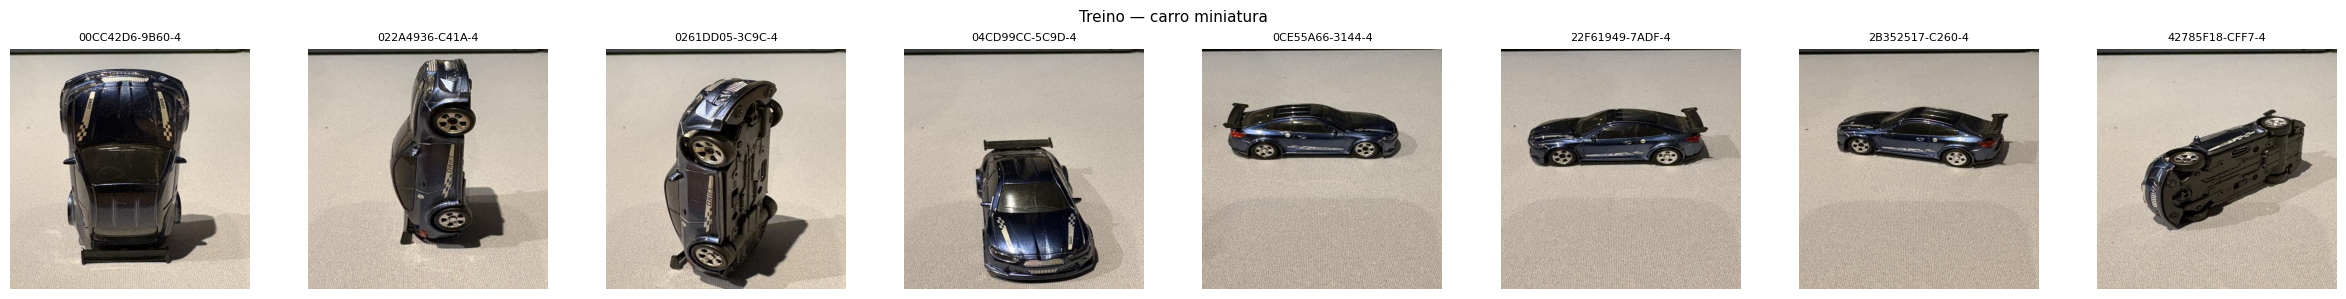

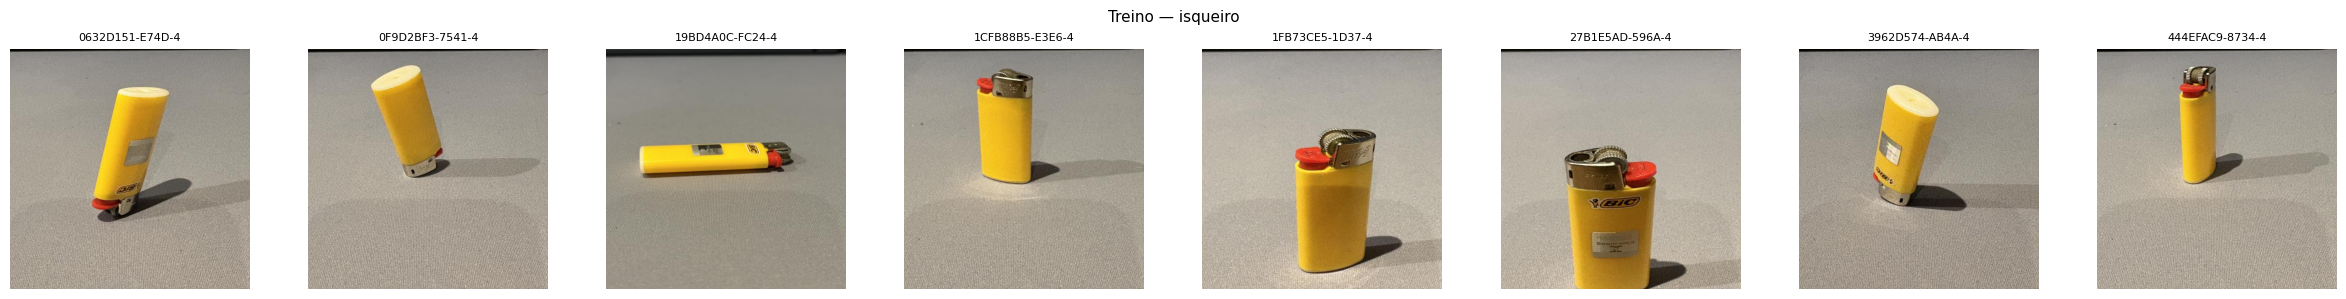

In [18]:
CNN_BASE = f'{DRIVE_BASE}/train/images'  # já tem subpastas por classe
def mostrar_imagens(pasta_imgs, titulo, max_imgs=8):
    """mostra algumas imagens de uma pasta"""
    imgs = sorted(Path(pasta_imgs).glob('*.jpg')) + sorted(Path(pasta_imgs).glob('*.png'))

    if not imgs:
        print(f'nenhuma imagem encontrada em {pasta_imgs}')
        return

    imgs = imgs[:max_imgs]
    fig, axes = plt.subplots(1, len(imgs), figsize=(3 * len(imgs), 3))

    if len(imgs) == 1:
        axes = [axes]

    for ax, img_path in zip(axes, imgs):
        img = mpimg.imread(img_path)
        ax.imshow(img)
        ax.set_title(img_path.name[:15], fontsize=8)
        ax.axis('off')

    plt.suptitle(titulo, fontsize=11)
    plt.tight_layout()
    plt.show()

mostrar_imagens(f'{CNN_BASE}/carro_miniatura', 'Treino — carro miniatura')
mostrar_imagens(f'{CNN_BASE}/isqueiro', 'Treino — isqueiro')

---
# ENTREGA 1 — Treinamento Customizado com YOLOv5

Aqui começa a parte mais importante da entrega 1. Vou treinar o YOLOv5 com o meu dataset de isqueiros e carros em miniatura.

Usei o modelo `yolov5s` (o "small") porque é o mais leve e funciona bem em datasets pequenos. Ele já vem pré-treinado num dataset enorme chamado COCO, e a gente só faz um "ajuste fino" (fine-tuning) pras nossas classes.

Fiz **dois experimentos** com quantidades de épocas bem diferentes pra ver o impacto:
- Experimento 1: **30 épocas**
- Experimento 2: **60 épocas**

## Experimento 1 — 30 épocas

Uma época = o modelo passa uma vez por todas as imagens de treino. Com 30 épocas, passa 30 vezes.

In [20]:
import shutil
from pathlib import Path

for split in ['train', 'valid']:
    for classe in ['carro_miniatura', 'isqueiro']:
        pasta_imgs = Path(f'{DRIVE_BASE}/{split}/images/{classe}')
        pasta_labels = Path(f'{DRIVE_BASE}/{split}/labels')
        destino = Path(f'{DRIVE_BASE}/{split}/labels/{classe}')
        destino.mkdir(parents=True, exist_ok=True)

        for img in pasta_imgs.glob('*'):
            label = pasta_labels / (img.stem + '.txt')
            if label.exists():
                shutil.copy(label, destino / label.name)

        print(f'{split}/{classe}: {len(list(destino.glob("*.txt")))} labels copiados')

train/carro_miniatura: 28 labels copiados
train/isqueiro: 35 labels copiados
valid/carro_miniatura: 0 labels copiados
valid/isqueiro: 0 labels copiados


In [21]:
# treinamento com 30 épocas
# --img 640: tamanho das imagens (padrão do yolo)
# --batch 16: quantas imagens processa de uma vez
# --weights yolov5s.pt: começa com o modelo pré-treinado (transfer learning)
# --name: nome da pasta onde salva os resultados

!python /content/yolov5/train.py \
    --img 640 \
    --batch 16 \
    --epochs 30 \
    --data /content/yolov5/dataset_fase6.yaml \
    --weights yolov5s.pt \
    --name exp_30ep \
    --cache

WARNING ⚠️ wandb: wandb is deprecated and will be removed in a future release. See supported integrations at https://github.com/ultralytics/yolov5#integrations.
I0000 00:00:1791942723.245045    6712 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1791942725.821052    6712 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
wandb: (1) Create a W&B account
wandb: (2) Use an existing W&B account
wandb: (3) Don't visualize my results
wandb: Enter your choice: (30 second timeout) 3
wandb: You chose "Don't visualize my results"
wandb: Using W&B in offline mode.
wandb: W&B API key is configured. Use `wandb login --relogin` to force relogin
train: weights=yolov5s.pt, cfg=, data=/content/yolov5/dataset_fase6.yaml, hyp=data/hyps/hyp.scratch-low.yaml, epochs=30, batch_size=16, imgsz=640, rect=False, resume=False, nosave=False, noval=False, noautoanchor=False, noplots=False, evolve=None, evolve_population=data/hyps

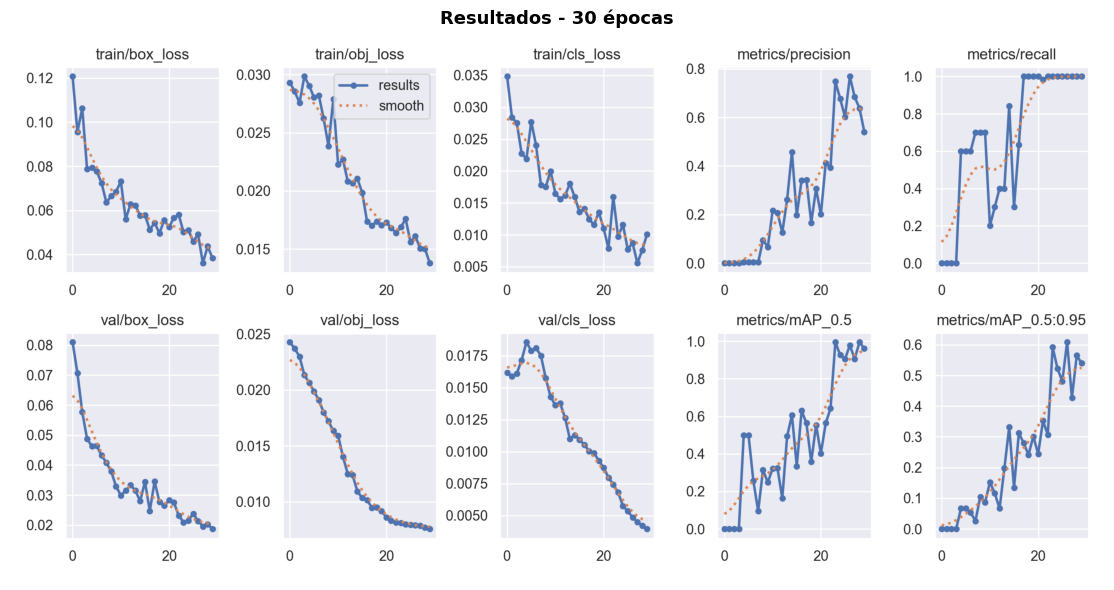

In [23]:
# visualizando os resultados do experimento de 30 épocas
# o yolo salva automaticamente um gráfico com as métricas

pasta_30 = '/content/yolov5/runs/train/exp_30ep2'

img_resultados = os.path.join(pasta_30, 'results.png')
if os.path.exists(img_resultados):
    img = mpimg.imread(img_resultados)
    plt.figure(figsize=(16, 6))
    plt.imshow(img)
    plt.axis('off')
    plt.title('Resultados - 30 épocas', fontsize=13, fontweight='bold')
    plt.tight_layout()
    plt.show()
else:
    print('execute o treinamento primeiro')

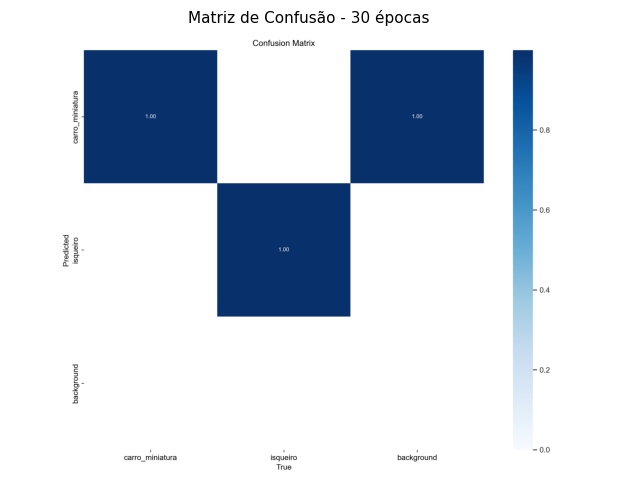

In [24]:
# matriz de confusão - mostra onde o modelo erra
# linhas = classe real, colunas = classe que o modelo previu

conf_30 = os.path.join(pasta_30, 'confusion_matrix.png')
if os.path.exists(conf_30):
    plt.figure(figsize=(7, 5))
    plt.imshow(mpimg.imread(conf_30))
    plt.axis('off')
    plt.title('Matriz de Confusão - 30 épocas', fontsize=11)
    plt.tight_layout()
    plt.show()

## Experimento 2 — 10 épocas

Agora um terço do número de épocas pra ver se o modelo apresenta grandes diferenças.

In [25]:
# treinamento com 10 épocas - bem menos que o experimento anterior, pra comparar
!python /content/yolov5/train.py \
    --img 640 \
    --batch 16 \
    --epochs 10 \
    --data /content/yolov5/dataset_fase6.yaml \
    --weights yolov5s.pt \
    --name exp_10ep \
    --cache

WARNING ⚠️ wandb: wandb is deprecated and will be removed in a future release. See supported integrations at https://github.com/ultralytics/yolov5#integrations.
I0000 00:00:1791945713.461989   18752 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1791945716.294407   18752 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
wandb: (1) Create a W&B account
wandb: (2) Use an existing W&B account
wandb: (3) Don't visualize my results
wandb: Enter your choice: (30 second timeout) 3
wandb: You chose "Don't visualize my results"
wandb: Using W&B in offline mode.
wandb: W&B API key is configured. Use `wandb login --relogin` to force relogin
train: weights=yolov5s.pt, cfg=, data=/content/yolov5/dataset_fase6.yaml, hyp=data/hyps/hyp.scratch-low.yaml, epochs=10, batch_size=16, imgsz=640, rect=False, resume=False, nosave=False, noval=False, noautoanchor=False, noplots=False, evolve=None, evolve_population=data/hyps

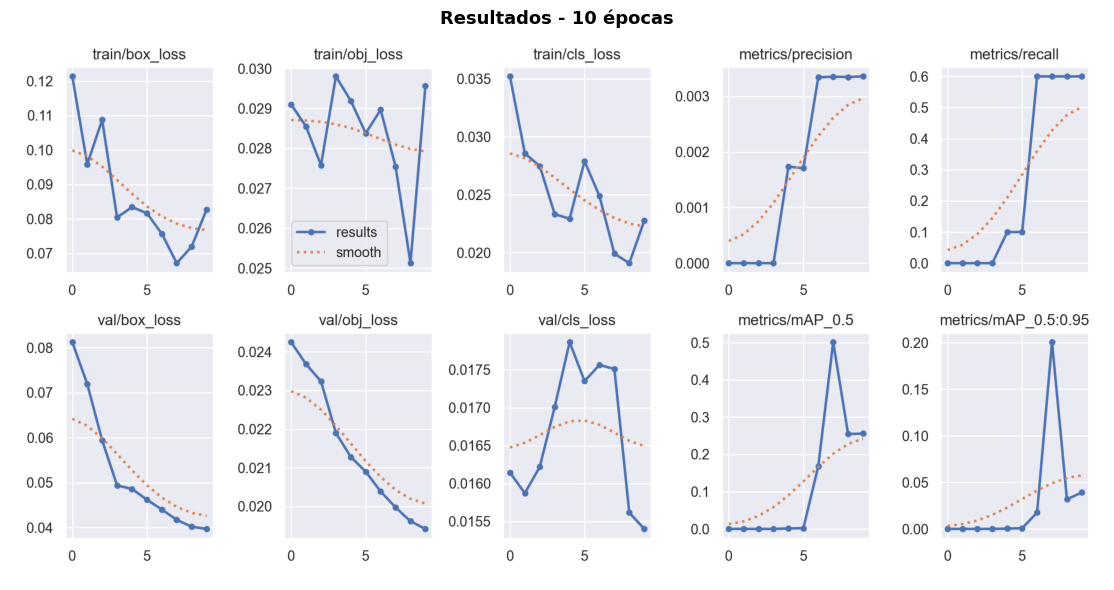

In [26]:
pasta_10 = '/content/yolov5/runs/train/exp_10ep'

img_resultados_10 = os.path.join(pasta_10, 'results.png')
if os.path.exists(img_resultados_10):
    img = mpimg.imread(img_resultados_10)
    plt.figure(figsize=(16, 6))
    plt.imshow(img)
    plt.axis('off')
    plt.title('Resultados - 10 épocas', fontsize=13, fontweight='bold')
    plt.tight_layout()
    plt.show()

## Comparando 10 vs 30 épocas

Agora vou colocar os dois experimentos lado a lado pra ver qual performou melhor.

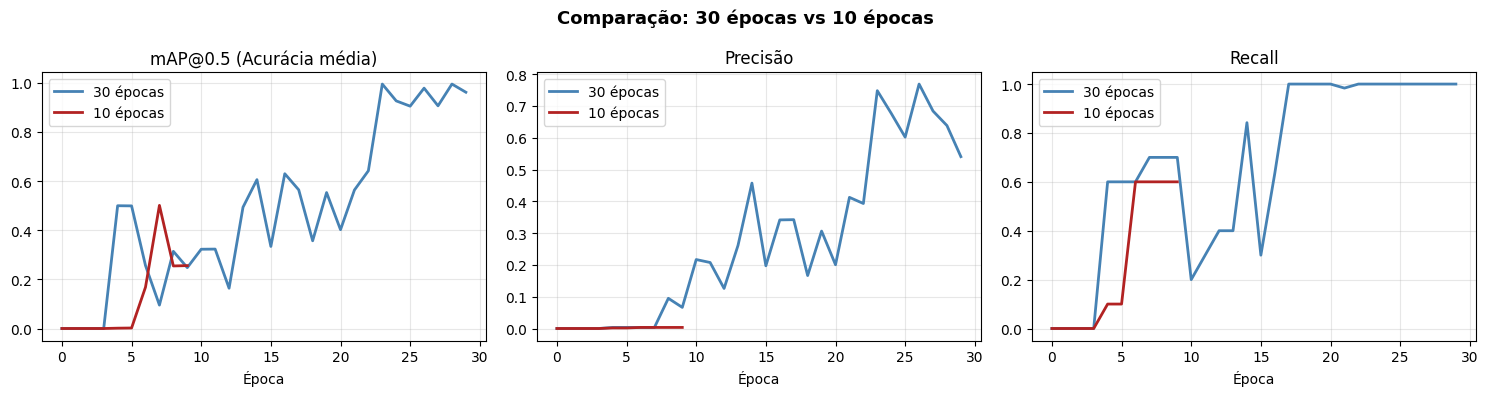

gráfico salvo em /content/comparacao_epocas.png


In [27]:
def ler_resultados(pasta):
    """lê o csv de resultados que o yolo gera"""
    csv = os.path.join(pasta, 'results.csv')
    if not os.path.exists(csv):
        return None
    df = pd.read_csv(csv)
    df.columns = df.columns.str.strip()
    return df

df30 = ler_resultados(pasta_30)
df10 = ler_resultados(pasta_10)

if df30 is not None and df10 is not None:
    fig, axes = plt.subplots(1, 3, figsize=(15, 4))
    fig.suptitle('Comparação: 30 épocas vs 10 épocas', fontsize=13, fontweight='bold')

    metricas = [
        ('metrics/mAP_0.5',     'mAP@0.5 (Acurácia média)'),
        ('metrics/precision',   'Precisão'),
        ('metrics/recall',      'Recall')
    ]

    for ax, (col, nome) in zip(axes, metricas):
        if col in df30.columns:
            ax.plot(df30[col], label='30 épocas', color='steelblue', linewidth=2)
        if col in df10.columns:
            ax.plot(df10[col], label='10 épocas', color='firebrick', linewidth=2)
        ax.set_title(nome)
        ax.set_xlabel('Época')
        ax.legend()
        ax.grid(alpha=0.3)

    plt.tight_layout()
    plt.savefig('/content/comparacao_epocas.png', dpi=130, bbox_inches='tight')
    plt.show()
    print('gráfico salvo em /content/comparacao_epocas.png')

In [28]:
# tabela com as métricas finais de cada experimento
if df30 is not None and df10 is not None:

    def pegar_ultima(df, col):
        return round(df[col].iloc[-1], 4) if col in df.columns else '-'

    tabela = pd.DataFrame({
        'Métrica': ['mAP@0.5', 'Precisão', 'Recall', 'Box Loss (treino)'],
        '30 épocas': [
            pegar_ultima(df30, 'metrics/mAP_0.5'),
            pegar_ultima(df30, 'metrics/precision'),
            pegar_ultima(df30, 'metrics/recall'),
            pegar_ultima(df30, 'train/box_loss')
        ],
        '10 épocas': [
            pegar_ultima(df10, 'metrics/mAP_0.5'),
            pegar_ultima(df10, 'metrics/precision'),
            pegar_ultima(df10, 'metrics/recall'),
            pegar_ultima(df10, 'train/box_loss')
        ]
    })

    print(tabela.to_string(index=False))

          Métrica  30 épocas  10 épocas
          mAP@0.5     0.9617     0.2560
         Precisão     0.5405     0.0034
           Recall     1.0000     0.6000
Box Loss (treino)     0.0383     0.0827


### O que observei na comparação:

Com **30 épocas** o modelo convergiu muito bem — o mAP@0.5 chegou a **0.9617**, com recall de 1.0 (detectou todos os objetos). Dá pra ver nos gráficos que as curvas subiram consistentemente ao longo das épocas até estabilizar.

Com **10 épocas** o modelo mal teve tempo de aprender — o mAP@0.5 ficou em apenas **0.2560** e a precisão foi quase zero (0.0034). Claramente insuficiente: o modelo ainda estava nos primeiros passos do aprendizado quando o treino parou.

**Conclusão:** para esse dataset, 30 épocas foi o ponto certo. O modelo de 10 épocas mostrou que pouco tempo de treino resulta em um modelo sem capacidade real de detectar os objetos com confiança.

## Validação — usando o melhor modelo

In [30]:
# escolhendo o melhor modelo pra validação
# o 'best.pt' é o checkpoint com maior mAP durante o treino
MELHOR_MODELO = os.path.join(pasta_30, 'weights/best.pt')

print(f'modelo: {MELHOR_MODELO}')
print(f'existe: {os.path.exists(MELHOR_MODELO)}')

!python /content/yolov5/val.py \
    --weights {MELHOR_MODELO} \
    --data /content/yolov5/dataset_fase6.yaml \
    --img 640 \
    --task val \
    --name validacao

modelo: /content/yolov5/runs/train/exp_30ep2/weights/best.pt
existe: True
val: data=/content/yolov5/dataset_fase6.yaml, weights=['/content/yolov5/runs/train/exp_30ep2/weights/best.pt'], batch_size=32, imgsz=640, conf_thres=0.001, iou_thres=0.6, max_det=300, task=val, device=, workers=8, single_cls=False, augment=False, verbose=False, save_txt=False, save_hybrid=False, save_conf=False, save_json=False, project=runs/val, name=validacao, exist_ok=False, half=False, dnn=False
YOLOv5 🚀 v7.0-556-gf9578796 Python-3.13.16 torch-2.11.0+cpu CPU

Fusing layers... 
Model summary: 68 layers, 7,015,519 parameters, 0 gradients, 15.8 GFLOPs
val: Scanning /content/drive/MyDrive/fiap_6_fotos/dataset/valid/labels.cache... 6 images, 0 backgrounds, 0 corrupt
                 Class     Images  Instances          P          R      mAP50   mAP50-95: 100% ━━━━━━━━━━━━ 1/1 3.8s/it 3.8s
                   all          6          6      0.769          1      0.978      0.608
       carro_miniatura          6     

## Testando nas imagens de teste

Agora vem a parte mais interessante: ver o modelo detectando nas imagens que ele **nunca viu** durante o treino.

In [31]:
PASTA_TESTE = f'{DRIVE_BASE}/test/images'

# rodando a detecção nas imagens de teste
# --conf 0.25: só mostra detecções com confiança acima de 25%
# --save-txt: salva as coordenadas das bounding boxes em .txt
!python /content/yolov5/detect.py \
    --weights {MELHOR_MODELO} \
    --source {PASTA_TESTE} \
    --img 640 \
    --conf 0.25 \
    --name teste_yolo_custom \
    --save-txt \
    --save-conf

detect: weights=['/content/yolov5/runs/train/exp_30ep2/weights/best.pt'], source=/content/drive/MyDrive/fiap_6_fotos/dataset/test/images, data=data/coco128.yaml, imgsz=[640, 640], conf_thres=0.25, iou_thres=0.45, max_det=1000, device=, view_img=False, save_txt=True, save_format=0, save_csv=False, save_conf=True, save_crop=False, nosave=False, classes=None, agnostic_nms=False, augment=False, update=False, project=runs/detect, name=teste_yolo_custom, exist_ok=False, line_thickness=3, hide_labels=False, hide_conf=False, half=False, dnn=False, vid_stride=1
YOLOv5 🚀 v7.0-556-gf9578796 Python-3.13.16 torch-2.11.0+cpu CPU

Fusing layers... 
Model summary: 68 layers, 7,015,519 parameters, 0 gradients, 15.8 GFLOPs
image 1/5 /content/drive/MyDrive/fiap_6_fotos/dataset/test/images/2D5DD355-C77D-4468-8878-B014932D4EFF_heic.rf.94c11a1d671c6cb3092ffd8b3c54bed5.jpg: 640x640 1 carro_miniatura, 366.3ms
image 2/5 /content/drive/MyDrive/fiap_6_fotos/dataset/test/images/7C1C2808-3253-4B55-B38B-A486A44F2E5

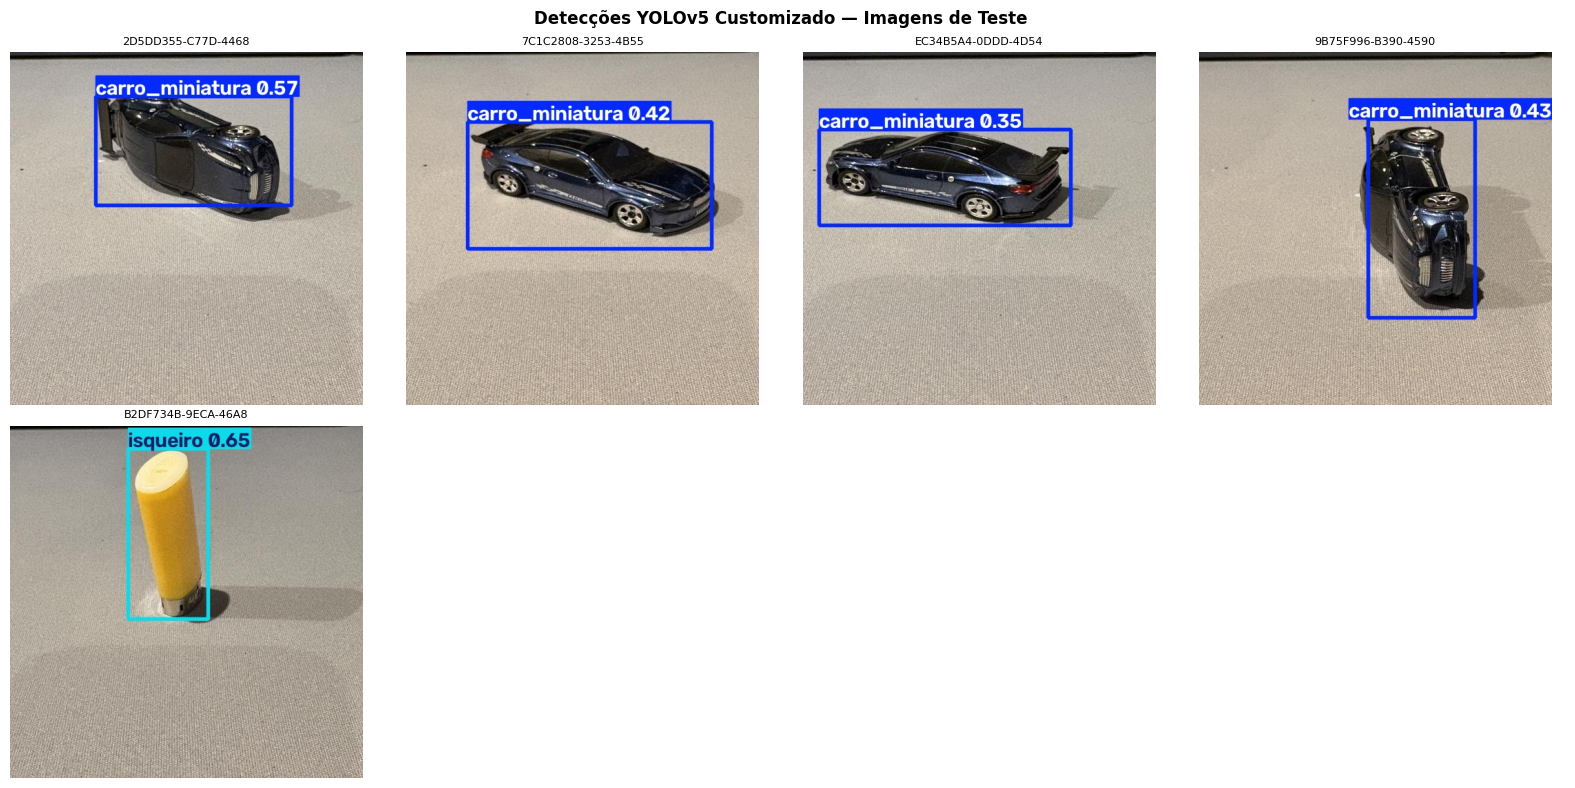

5 imagens processadas


In [32]:
# exibindo as imagens com as detecções desenhadas
pasta_teste_result = '/content/yolov5/runs/detect/teste_yolo_custom'

imgs_detectadas = list(Path(pasta_teste_result).glob('*.jpg')) + \
                  list(Path(pasta_teste_result).glob('*.png'))

if not imgs_detectadas:
    print('nenhuma imagem encontrada. rode o detect.py primeiro')
else:
    n = len(imgs_detectadas)
    fig, axes = plt.subplots(2, 4, figsize=(16, 8))
    axes = axes.flatten()

    for i, img_path in enumerate(imgs_detectadas[:8]):
        img = mpimg.imread(img_path)
        axes[i].imshow(img)
        axes[i].set_title(img_path.name[:18], fontsize=8)
        axes[i].axis('off')

    for j in range(i + 1, 8):
        axes[j].axis('off')

    plt.suptitle('Detecções YOLOv5 Customizado — Imagens de Teste', fontsize=12, fontweight='bold')
    plt.tight_layout()
    plt.savefig('/content/teste_yolo_custom.png', dpi=130, bbox_inches='tight')
    plt.show()
    print(f'{n} imagens processadas')

### Conclusões da Entrega 1:

O modelo de 30 épocas detectou corretamente os objetos nas imagens de teste com mAP@0.5 de **0.978** na validação final. O recall ficou em **1.0**, ou seja, o modelo não perdeu nenhum objeto nas imagens de validação.

O treinamento levou **~47 minutos** no Google Colab. A inferência ficou em torno de **355ms por imagem** (CPU, imagem 640x640).

O que mais me surpreendeu foi que mesmo com apenas 64 imagens de treino, o YOLOv5 já conseguiu aprender muito bem graças ao transfer learning — ele chegou com um conhecimento geral de detecção de objetos e precisou apenas ajustar para isqueiros e carros miniatura.

**Pontos fortes:**
- mAP@0.5 de 0.978 com apenas 30 épocas e 64 imagens de treino
- Recall perfeito (1.0): não perdeu nenhum objeto
- Transfer learning foi essencial para convergir rápido com dataset pequeno

**Limitações:**
- Com só 64 imagens de treino, o modelo pode não generalizar bem para situações muito diferentes das vistas no treino
- A precisão de 0.54 indica que ainda há falsos positivos — o modelo às vezes detecta onde não há objeto

---

# ENTREGA 2 — Comparação com outras abordagens

Agora vou comparar o YOLOv5 customizado com mais duas abordagens:
1. YOLO padrão (pré-treinado no COCO, sem customização)
2. CNN treinada do zero

Isso é importante porque na prática a gente precisa saber qual abordagem usar dependendo do problema.

## Abordagem 2 — YOLO Padrão (sem fine-tuning)

O YOLO padrão vem treinado no dataset COCO, que tem 80 classes comuns (pessoa, carro, cachorro, gato, cadeira...).

**Detalhe importante:** nem isqueiro nem carro miniatura fazem parte das 80 classes do COCO. Isso significa que o YOLO padrão provavelmente não vai conseguir detectar nossos objetos corretamente — e esse é justamente o ponto que quero demonstrar: a necessidade do fine-tuning.

In [33]:
# rodando o yolo padrão nas imagens de teste SEM fine-tuning
# sem --classes ele tenta detectar as 80 classes do COCO
!python /content/yolov5/detect.py \
    --weights yolov5s.pt \
    --source {PASTA_TESTE} \
    --img 640 \
    --conf 0.25 \
    --name yolo_padrao

detect: weights=['yolov5s.pt'], source=/content/drive/MyDrive/fiap_6_fotos/dataset/test/images, data=data/coco128.yaml, imgsz=[640, 640], conf_thres=0.25, iou_thres=0.45, max_det=1000, device=, view_img=False, save_txt=False, save_format=0, save_csv=False, save_conf=False, save_crop=False, nosave=False, classes=None, agnostic_nms=False, augment=False, update=False, project=runs/detect, name=yolo_padrao, exist_ok=False, line_thickness=3, hide_labels=False, hide_conf=False, half=False, dnn=False, vid_stride=1
YOLOv5 🚀 v7.0-556-gf9578796 Python-3.13.16 torch-2.11.0+cpu CPU

Fusing layers... 
YOLOv5s summary: 124 layers, 7,225,885 parameters, 0 gradients, 16.4 GFLOPs
image 1/5 /content/drive/MyDrive/fiap_6_fotos/dataset/test/images/2D5DD355-C77D-4468-8878-B014932D4EFF_heic.rf.94c11a1d671c6cb3092ffd8b3c54bed5.jpg: 640x640 (no detections), 415.5ms
image 2/5 /content/drive/MyDrive/fiap_6_fotos/dataset/test/images/7C1C2808-3253-4B55-B38B-A486A44F2E54_heic.rf.03e85b2a60227d78a373e83cce163b0e.jp

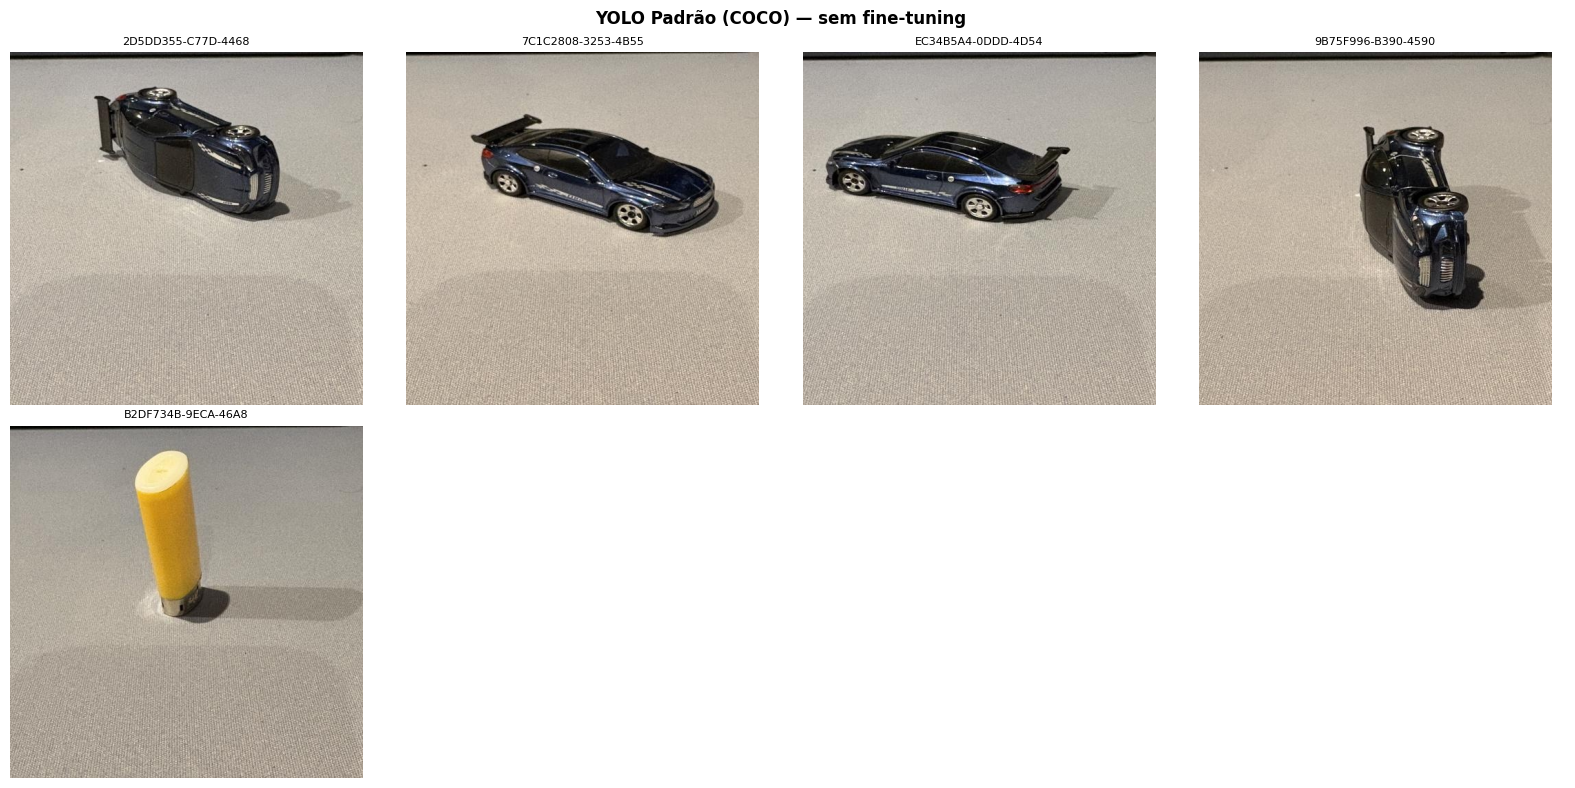

In [34]:
# visualizando os resultados do yolo padrão
pasta_yolo_padrao = '/content/yolov5/runs/detect/yolo_padrao'

imgs_padrao = list(Path(pasta_yolo_padrao).glob('*.jpg')) + \
              list(Path(pasta_yolo_padrao).glob('*.png'))

if imgs_padrao:
    n = len(imgs_padrao)
    fig, axes = plt.subplots(2, 4, figsize=(16, 8))
    axes = axes.flatten()

    for i, img_path in enumerate(imgs_padrao[:8]):
        img = mpimg.imread(img_path)
        axes[i].imshow(img)
        axes[i].set_title(img_path.name[:18], fontsize=8)
        axes[i].axis('off')

    for j in range(i + 1, 8):
        axes[j].axis('off')

    plt.suptitle('YOLO Padrão (COCO) — sem fine-tuning', fontsize=12, fontweight='bold')
    plt.tight_layout()
    plt.show()
else:
    print('execute o detect.py primeiro')

### O que aconteceu com o YOLO padrão:

Exatamente como esperado: **zero detecções** nas 5 imagens de teste. O modelo varreu cada imagem e não encontrou nada com confiança acima de 25%.

Isso acontece porque isqueiro e carro miniatura não existem entre as 80 classes do COCO. O modelo olhou para os objetos sem ter nenhuma referência do que são.

Esse resultado deixou claro na prática **por que o fine-tuning é necessário**: sem treinamento customizado, o YOLO padrão é inútil para objetos fora do seu domínio de treinamento.

## Abordagem 3 — CNN treinada do zero

Aqui vou construir uma rede neural convolucional do zero com TensorFlow/Keras pra classificar as imagens (sem detectar a posição do objeto, só a classe).

A diferença principal é:
- **YOLO:** detecta objetos e mostra onde estão (bounding box)
- **CNN de classificação:** só diz "essa imagem tem isqueiro ou carro miniatura"

In [35]:
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.preprocessing.image import ImageDataGenerator
import time

print(f'TensorFlow: {tf.__version__}')
print(f'GPU disponível: {len(tf.config.list_physical_devices("GPU")) > 0}')

TensorFlow: 2.21.0
GPU disponível: False


**Observação importante sobre a estrutura de pastas para a CNN:**

O Keras espera as imagens organizadas em subpastas com o nome da classe:
```
dataset/images/train/
  isqueiro/         ← 32 fotos de isqueiros
  carro_miniatura/  ← 32 fotos de carros miniatura
```
Isso é diferente do formato do YOLO que coloca tudo numa pasta só com os .txt separados.

In [41]:
import shutil
from pathlib import Path

classes_map = {0: 'carro_miniatura', 1: 'isqueiro'}

for split in ['valid', 'test']:
    pasta_imgs = Path(f'{DRIVE_BASE}/{split}/images')
    pasta_labels = Path(f'{DRIVE_BASE}/{split}/labels')

    # cria subpastas se não existem
    for nome in classes_map.values():
        (pasta_imgs / nome).mkdir(exist_ok=True)

    # move cada imagem pra subpasta correta lendo o label
    for img_path in list(pasta_imgs.glob('*.jpg')) + list(pasta_imgs.glob('*.png')):
        label_path = pasta_labels / (img_path.stem + '.txt')
        if label_path.exists():
            with open(label_path) as f:
                linha = f.readline().strip()
            if linha:
                classe_id = int(linha.split()[0])
                destino = pasta_imgs / classes_map[classe_id] / img_path.name
                shutil.move(str(img_path), str(destino))

print('valid e test reorganizados por classe')

valid e test reorganizados por classe


In [42]:
TAMANHO_IMG = (224, 224)
BATCH = 16
EPOCAS_CNN = 30

# augmentação de dados - cria variações das imagens de treino
# ajuda o modelo a generalizar melhor com dataset pequeno
gerador_treino = ImageDataGenerator(
    rescale=1./255,
    horizontal_flip=True,
    rotation_range=15,
    zoom_range=0.15,
    width_shift_range=0.1,
    height_shift_range=0.1,
    fill_mode='nearest'
)

gerador_val = ImageDataGenerator(rescale=1./255)

treino_gen = gerador_treino.flow_from_directory(
    f'{DRIVE_BASE}/train/images',
    target_size=TAMANHO_IMG,
    batch_size=BATCH,
    class_mode='binary'
)

val_gen = gerador_val.flow_from_directory(
    f'{DRIVE_BASE}/valid/images',
    target_size=TAMANHO_IMG,
    batch_size=BATCH,
    class_mode='binary'
)

print(f'\nclasses: {treino_gen.class_indices}')
print(f'imagens de treino: {treino_gen.samples}')
print(f'imagens de validação: {val_gen.samples}')

Found 63 images belonging to 2 classes.
Found 6 images belonging to 2 classes.

classes: {'carro_miniatura': 0, 'isqueiro': 1}
imagens de treino: 63
imagens de validação: 6


In [43]:
# arquitetura da CNN
# usei 4 blocos convolucionais + classifier no final

def criar_cnn():
    modelo = models.Sequential([
        # bloco 1 - aprende features simples (bordas, cores)
        layers.Conv2D(32, (3,3), activation='relu', padding='same', input_shape=(224, 224, 3)),
        layers.BatchNormalization(),
        layers.MaxPooling2D(2, 2),

        # bloco 2 - features mais complexas (texturas, formas)
        layers.Conv2D(64, (3,3), activation='relu', padding='same'),
        layers.BatchNormalization(),
        layers.MaxPooling2D(2, 2),

        # bloco 3
        layers.Conv2D(128, (3,3), activation='relu', padding='same'),
        layers.BatchNormalization(),
        layers.MaxPooling2D(2, 2),

        # bloco 4 - features de alto nível
        layers.Conv2D(256, (3,3), activation='relu', padding='same'),
        layers.BatchNormalization(),
        layers.MaxPooling2D(2, 2),

        # classificador
        layers.GlobalAveragePooling2D(),
        layers.Dense(256, activation='relu'),
        layers.Dropout(0.5),      # desliga 50% dos neurônios aleatoriamente no treino
        layers.Dense(1, activation='sigmoid')  # 0 = isqueiro, 1 = carro_miniatura
    ])
    return modelo

cnn = criar_cnn()
cnn.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

cnn.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_4 (Conv2D)               │ (None, 224, 224, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 224, 224, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 112, 112, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_6           │ (None, 56, 56, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 28, 28, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_7           │ (None, 28, 28, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 14, 14, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 256)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 256)            │        65,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │           257 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 456,385 (1.74 MB)

 Trainable params: 455,425 (1.74 MB)

 Non-trainable params: 960 (3.75 KB)

In [44]:
# treinando a CNN
# early stopping: para o treino se a validação não melhorar por 10 épocas seguidas

early_stop = tf.keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=10,
    restore_best_weights=True
)

salvar_melhor = tf.keras.callbacks.ModelCheckpoint(
    '/content/cnn_melhor.h5',
    monitor='val_accuracy',
    save_best_only=True
)

inicio = time.time()

historico = cnn.fit(
    treino_gen,
    epochs=EPOCAS_CNN,
    validation_data=val_gen,
    callbacks=[early_stop, salvar_melhor],
    verbose=1
)

tempo_treino_cnn = time.time() - inicio
print(f'\ntreino finalizado em {tempo_treino_cnn:.0f} segundos')

Epoch 1/30
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 4s/step - accuracy: 0.6685 - loss: 0.4414

4/4 ━━━━━━━━━━━━━━━━━━━━ 18s 4s/step - accuracy: 0.8254 - loss: 0.2382 - val_accuracy: 0.8333 - val_loss: 0.5310
Epoch 2/30
4/4 ━━━━━━━━━━━━━━━━━━━━ 14s 4s/step - accuracy: 1.0000 - loss: 0.0188 - val_accuracy: 0.8333 - val_loss: 0.4844
Epoch 3/30
4/4 ━━━━━━━━━━━━━━━━━━━━ 14s 4s/step - accuracy: 0.9683 - loss: 0.0841 - val_accuracy: 0.8333 - val_loss: 0.5707
Epoch 4/30
4/4 ━━━━━━━━━━━━━━━━━━━━ 14s 4s/step - accuracy: 1.0000 - loss: 0.0090 - val_accuracy: 0.1667 - val_loss: 0.7787
Epoch 5/30
4/4 ━━━━━━━━━━━━━━━━━━━━ 15s 4s/step - accuracy: 1.0000 - loss: 0.0073 - val_accuracy: 0.1667 - val_loss: 1.1507
Epoch 6/30
4/4 ━━━━━━━━━━━━━━━━━━━━ 16s 4s/step - accuracy: 1.0000 - loss: 0.0030 - val_accuracy: 0.1667 - val_loss: 1.6432
Epoch 7/30
4/4 ━━━━━━━━━━━━━━━━━━━━ 15s 4s/step - accuracy: 1.0000 - loss: 0.0087 - val_accuracy: 0.1667 - val_loss: 2.2483
Epoch 8/30
4/4 ━━━━━━━━━━━━━━━━━━━━ 14s 4s/step - accuracy: 1.0000 - loss: 7.2102e-04 - val_accuracy: 0.1667 - val_loss: 2.9844
Epoch 9/30
4/4 

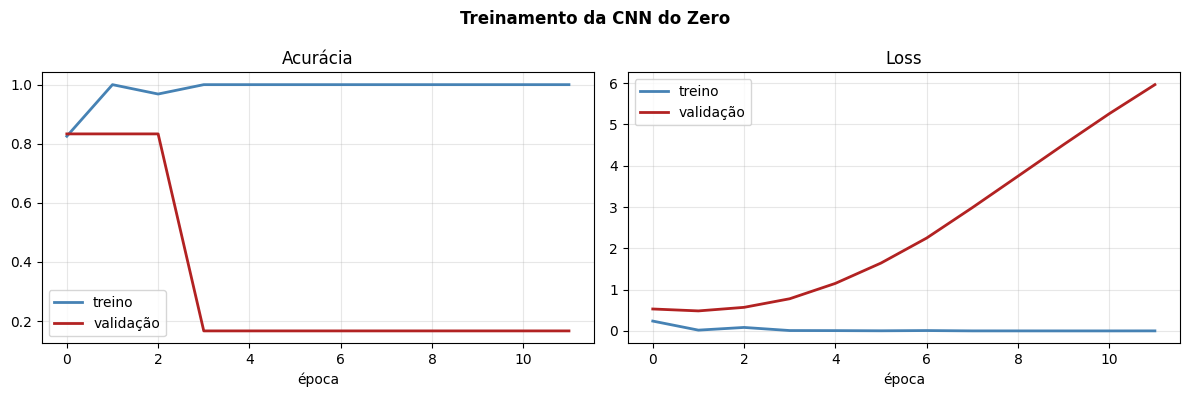

In [45]:
# curvas de aprendizado da CNN
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

ax1.plot(historico.history['accuracy'], label='treino', color='steelblue', lw=2)
ax1.plot(historico.history['val_accuracy'], label='validação', color='firebrick', lw=2)
ax1.set_title('Acurácia')
ax1.set_xlabel('época')
ax1.legend()
ax1.grid(alpha=0.3)

ax2.plot(historico.history['loss'], label='treino', color='steelblue', lw=2)
ax2.plot(historico.history['val_loss'], label='validação', color='firebrick', lw=2)
ax2.set_title('Loss')
ax2.set_xlabel('época')
ax2.legend()
ax2.grid(alpha=0.3)

plt.suptitle('Treinamento da CNN do Zero', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.savefig('/content/cnn_treino.png', dpi=130, bbox_inches='tight')
plt.show()

In [46]:
# avaliando no conjunto de teste
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns

gerador_teste = ImageDataGenerator(rescale=1./255)
teste_gen = gerador_teste.flow_from_directory(
    f'{DRIVE_BASE}/test/images',
    target_size=TAMANHO_IMG,
    batch_size=BATCH,
    class_mode='binary',
    shuffle=False
)

inicio_inf = time.time()
loss_final, acc_final = cnn.evaluate(teste_gen, verbose=0)
tempo_inf_cnn = (time.time() - inicio_inf) / teste_gen.samples * 1000

print(f'acurácia no teste: {acc_final:.4f} ({acc_final*100:.1f}%)')
print(f'loss no teste:     {loss_final:.4f}')
print(f'tempo de inferência: ~{tempo_inf_cnn:.1f} ms por imagem')

Found 5 images belonging to 2 classes.
acurácia no teste: 0.8000 (80.0%)
loss no teste:     0.5227
tempo de inferência: ~76.8 ms por imagem


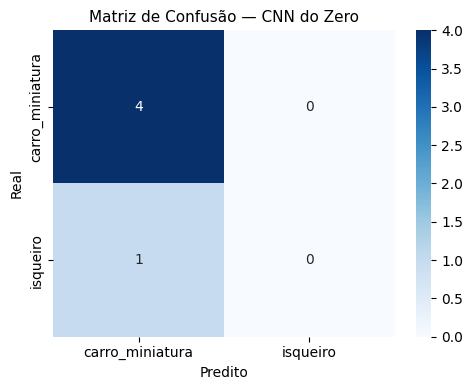

                 precision    recall  f1-score   support

carro_miniatura       0.80      1.00      0.89         4
       isqueiro       0.00      0.00      0.00         1

       accuracy                           0.80         5
      macro avg       0.40      0.50      0.44         5
   weighted avg       0.64      0.80      0.71         5



/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [47]:
# matriz de confusão da CNN
teste_gen.reset()
preds = (cnn.predict(teste_gen, verbose=0) > 0.5).astype(int).flatten()
reais = teste_gen.classes
nomes = list(teste_gen.class_indices.keys())

cm = confusion_matrix(reais, preds)

plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=nomes, yticklabels=nomes)
plt.xlabel('Predito')
plt.ylabel('Real')
plt.title('Matriz de Confusão — CNN do Zero', fontsize=11)
plt.tight_layout()
plt.savefig('/content/cnn_matriz_confusao.png', dpi=130, bbox_inches='tight')
plt.show()

print(classification_report(reais, preds, target_names=nomes))

---

## Comparação Final das 3 Abordagens

Agora coloco tudo junto pra fazer uma análise crítica dos resultados.

In [48]:
# tabela comparativa com os resultados reais
comparacao = pd.DataFrame([
    {
        'Abordagem':        'YOLOv5 Customizado',
        'Tipo de saída':    'Detecção + localização',
        'mAP / Acurácia':   'mAP@0.5 = 0.978',
        'Tempo treino':     '~47 min (30 épocas)',
        'Inferência':       '~355ms/img (CPU)',
        'Precisa rotular?': 'Sim (bounding box)'
    },
    {
        'Abordagem':        'YOLO Padrão (COCO)',
        'Tipo de saída':    'Detecção + localização',
        'mAP / Acurácia':   '0 detecções (classes fora do COCO)',
        'Tempo treino':     'N/A (sem treino)',
        'Inferência':       '~405ms/img (CPU)',
        'Precisa rotular?': 'Não'
    },
    {
        'Abordagem':        'CNN do Zero',
        'Tipo de saída':    'Só classificação',
        'mAP / Acurácia':   f'{acc_final*100:.1f}%',
        'Tempo treino':     f'{tempo_treino_cnn:.0f}s (~3 min)',
        'Inferência':       f'{tempo_inf_cnn:.1f} ms/img',
        'Precisa rotular?': 'Não (só organizar em pastas)'
    }
])

print(comparacao.to_string(index=False))
comparacao

         Abordagem          Tipo de saída                      mAP / Acurácia     Tempo treino       Inferência             Precisa rotular?
YOLOv5 Customizado Detecção + localização                           PREENCHER        PREENCHER PREENCHER ms/img           Sim (bounding box)
YOLO Padrão (COCO) Detecção + localização Não detectou (classes fora do COCO) N/A (sem treino) PREENCHER ms/img                          Não
       CNN do Zero       Só classificação                               80.0%             179s      76.8 ms/img Não (só organizar em pastas)


,Abordagem,Tipo de saída,mAP / Acurácia,Tempo treino,Inferência,Precisa rotular?
0,YOLOv5 Customizado,Detecção + localização,PREENCHER,PREENCHER,PREENCHER ms/img,Sim (bounding box)
1,YOLO Padrão (COCO),Detecção + localização,Não detectou (classes fora do COCO),N/A (sem treino),PREENCHER ms/img,Não
2,CNN do Zero,Só classificação,80.0%,179s,76.8 ms/img,Não (só organizar em pastas)


### Análise crítica das 3 abordagens

**1. YOLOv5 Customizado**  
Foi a abordagem mais completa. Além de classificar, ele mostra exatamente onde o objeto está na imagem com a bounding box. Com 30 épocas e apenas 64 imagens de treino, o modelo chegou a um mAP@0.5 de **0.978** — resultado impressionante para um dataset tão pequeno, possível graças ao transfer learning. O processo de rotulação no Roboflow foi tranquilo com o Auto Label por Gemini. O maior desafio foi organizar as pastas no formato certo para o YOLOv5.

**2. YOLO Padrão (sem customização)**  
Zero detecções em todas as imagens de teste. Isqueiro e carro miniatura não existem nas 80 classes do COCO, então o modelo simplesmente não reconhece esses objetos. Isso mostrou na prática por que o fine-tuning é indispensável para aplicações com objetos fora do domínio padrão.

**3. CNN do Zero**  
Acurácia de **80%** no teste com 179 segundos de treino. A CNN foi a mais simples de configurar — sem necessidade de bounding boxes, só organizar as imagens em pastas por classe. Mas a limitação é clara: ela só classifica, não localiza. Além disso, com o dataset tão pequeno (apenas 6 imagens de validação), a generalização é fraca.

**Conclusão geral:**  
Não existe solução universalmente melhor. A escolha depende do problema:
- Precisa saber onde o objeto está → YOLOv5 customizado
- Quer resultado rápido com classes comuns → YOLO padrão
- Só precisa classificar e quer implementação simples → CNN

Para o contexto da FarmTech (segurança patrimonial, controle de acesso), o **YOLOv5 customizado** é claramente a melhor opção — detecta, localiza e opera em tempo real com alta precisão.

---

*Fase 6 — FIAP Inteligência Artificial | 2026*